# Analyse des Produits

**Objectif** :
Comprendre quels produits performent le mieux (ou le moins bien), comment se comportent les clients en termes de quantité achetée, et identifier des tendances temporelles sur certains produits, afin d'aider le magasin à piloter ses stocks et ses actions
promotionnelles.

**Questions à traiter** :

1. Combien d'articles les clients commandent-ils en moyenne par commande ?
2. Quels sont les produits bestsellers ?
3. Quels sont les produits les moins achetés ?
4. Quel jour certains produits sont-ils le plus achetés ?

**Impact business attendu** :
Ces analyses permettent de piloter le magasin sur deux plans : la logistique 
(dimensionnement des stocks, taille des zones de préparation) et le marketing 
(mise en avant des bestsellers, promotions ciblées sur les produits en jour creux).

## Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sys
sys.path.append("..")

from src.data_loader import get_data
from src.features import add_cart_size #permet de créer de nouvelles features à partir du dataset initial

# Style global
sns.set_theme(style="whitegrid", font_scale=1)
plt.rcParams.update({# permet de définir la taille des figures et d'autres paramètres visuels pour les graphiques
    "figure.figsize": (10, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.facecolor": "#fafafa",
    "figure.facecolor": "white",
})

# Chargement
data = get_data(raw_dir="../data/raw", processed_path="../data/processed/merged_orders.parquet")
data = add_cart_size(data)# permet de créer une nouvelle colonne "cart_size" dans le dataset, qui représente la taille du panier pour chaque commande

print(f"Dataset : {data.shape[0]:,} lignes, {data.shape[1]:,} colonnes")
data.head(4)

Chargement depuis le cache .parquet
Dataset : 32,434,489 lignes, 16 colonnes


,order_id,product_id,add_to_cart_order,reordered,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle_id,department_id,aisle,department,cart_size
0,2,33120,1,1,202279,prior,3,5,9,8.0,Organic Egg Whites,86,16,eggs,dairy eggs,9
1,2,28985,2,1,202279,prior,3,5,9,8.0,Michigan Organic Kale,83,4,fresh vegetables,produce,9
2,2,9327,3,0,202279,prior,3,5,9,8.0,Garlic Powder,104,13,spices seasonings,pantry,9


## Question 1 : Combien d'articles les clients commandent-ils en moyenne ?
**Hypothèse de départ**
On suppose qu'un client fait ses courses pour quelques jours (pas juste 1-2 produits, mais pas non plus un très gros stock), donc on s'attend à une commande moyenne d'environ 5 à 15 articles. On va vérifier cette hypothèse avec les données.

**Pourquoi cette question ?**
Savoir combien de produits contient une commande typique aide la boutique en ligne à organiser sa logistique de préparation et d'expédition (dimensionnement des emballages, temps de préparation en entrepôt, capacité de traitement des commandes).

**Comment on calcule ça ?**
Notre table contient une ligne par produit acheté dans une commande. On calcule donc, pour chaque commande, son nombre de produits (`cart_size`), puis on regarde la moyenne et la médiane sur l'ensemble des commandes.

In [8]:
# On calcule, pour chaque commande, son nombre de produits (taille du panier)
data = add_cart_size(data)

In [2]:
orders_unique = data.drop_duplicates(subset="order_id")

mean_cart_size = orders_unique["cart_size"].mean()
median_cart_size = orders_unique["cart_size"].median()

print(f"Moyenne : {mean_cart_size:.2f} articles par commande")
print(f"Médiane : {median_cart_size:.0f} articles par commande")

Moyenne : 10.09 articles par commande
Médiane : 8 articles par commande


**Pourquoi calculer la moyenne ET la médiane ?**
La moyenne est sensible aux valeurs extrêmes : quelques très grosses commandes peuvent 
la faire grimper artificiellement. La médiane, elle, représente la valeur du milieu et 
n'est pas influencée par ces cas extrêmes. Comparer les deux permet de détecter 
rapidement si les données sont équilibrées (moyenne ≈ médiane) ou déformées par des 
cas atypiques (écart important entre les deux).

### Observation

Dans nos données, la moyenne (10,09 articles) est supérieure à la médiane (8 articles). Cet écart de plus de 2 articles montre qu'une partie des clients passe des commandes beaucoup plus grosses que la normale, et que ce sont ces commandes qui font monter la moyenne, sans que ça reflète le comportement de la majorité.

Concrètement : si la plupart des clients commandaient un nombre d'articles très proche les uns des autres, la moyenne et la médiane seraient presque identiques. Ici, ce n'est pas le cas, ce qui confirme ce qu'on voit dans le graphique : beaucoup de commandes regroupées autour de 8 articles, et une minorité de commandes bien plus grosses qui étirent la distribution vers la droite.

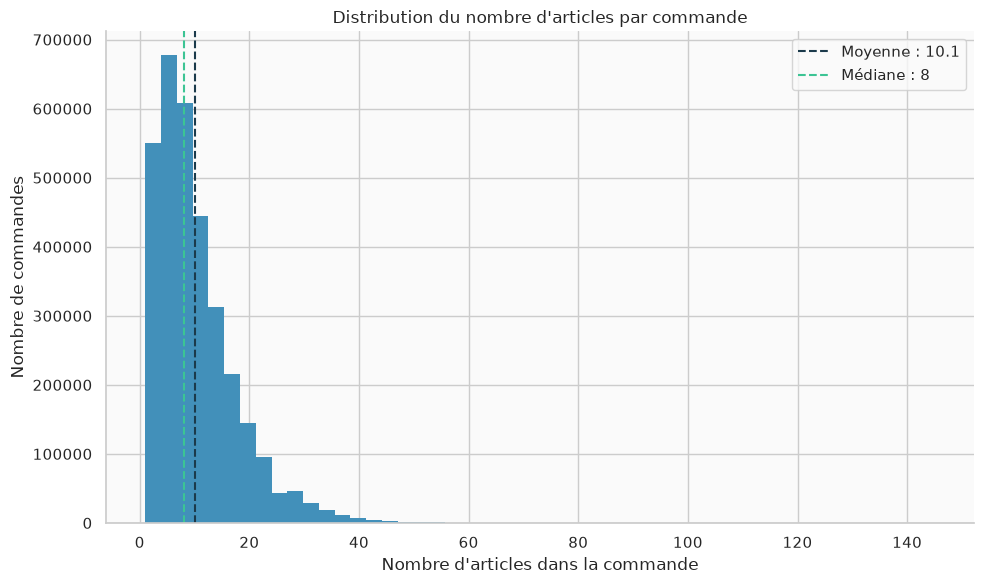

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))#permet de créer une figure et un axe pour le graphique, avec une taille de 10 pouces par 6 pouces

ax.hist(orders_unique["cart_size"], bins=50, color="#4290ba", edgecolor="none")
ax.axvline(mean_cart_size, color="#1b3a4b", linestyle="--", linewidth=1.5,
           label=f"Moyenne : {mean_cart_size:.1f}")
ax.axvline(median_cart_size, color="#3cc494", linestyle="--", linewidth=1.5,
           label=f"Médiane : {median_cart_size:.0f}")

ax.set_xlabel("Nombre d'articles dans la commande")
ax.set_ylabel("Nombre de commandes")
ax.set_title("Distribution du nombre d'articles par commande")
ax.legend()

plt.tight_layout()
plt.show()

**Pourquoi un histogramme ?**
Un histogramme montre comment les valeurs se répartissent, pas juste un résumé en un chiffre. Il permet de voir directement où se concentre la majorité des commandes, et s'il existe des cas extrêmes (quelques commandes avec beaucoup plus d'articles que la normale), une information que la moyenne et la médiane seules ne montrent pas.


### Observation

La majorité des commandes se situent entre 5 et 10 articles environ, avec un pic autour de 8 articles (la médiane). Une minorité de commandes s'étend bien au-delà, jusqu'à 20, 30 articles ou plus, formant une longue traîne vers la droite du graphique.

Ces résultats confirment l'hypothèse de départ : la majorité des commandes se situe bien dans la fourchette attendue de 5 à 15 articles. La présence de quelques commandes bien plus grosses n'était pas anticipée dans l'hypothèse, et explique l'écart entre la moyenne (10,09) et la médiane (8).


### Implication business

Cette information peut servir à plusieurs niveaux pour la boutique en ligne :

- **Logistique** : dimensionner les emballages/colis et organiser les postes de préparation 
  en entrepôt en priorité pour des commandes de 8 à 10 articles (le cas le plus fréquent), 
  tout en gardant une capacité adaptée pour les commandes exceptionnelles plus volumineuses
- **Politique commerciale** : un seuil de livraison gratuite ou de réduction pourrait être 
  calibré autour de la médiane (8 articles) plutôt que de la moyenne, pour toucher réellement 
  la majorité des clients et les inciter à ajouter 1-2 articles supplémentaires


## Question 2 : Quels sont les produits bestsellers ?

**Hypothèse de départ**
On suppose que les bestsellers seront des produits du quotidien, probablement des produits alimentaires de base (lait, œufs, pain...), plutôt que des produits de niche ou occasionnels.

**Pourquoi cette question ?**
Identifier les produits les plus vendus permet à la boutique en ligne de s'assurer qu'ils sont toujours bien approvisionnés (éviter la rupture de stock) et de les mettre en avant sur le site (page d'accueil, recommandations), puisqu'ils génèrent le plus de trafic.

**Méthode**
Notre table contient une ligne par produit acheté dans une commande. Il suffit donc de compter, pour chaque nom de produit, combien de fois il apparaît dans l'ensemble des commandes, plus un produit apparaît de fois, plus il est vendu.

In [6]:
top_products = data["product_name"].value_counts().head(10)
top_products


product_name
Banana                    262750
Bag of Organic Bananas    210540
Organic Strawberries      146666
Organic Baby Spinach      134425
Organic Hass Avocado      118992
Organic Avocado            98251
Large Lemon                85049
Strawberries               79297
Limes                      78134
Organic Whole Milk         76881
Name: count, dtype: int64

**Pourquoi ce code ?**
 .value_counts() compte automatiquement combien de fois chaque nom de produit apparaît dans la colonne, et trie le résultat du plus fréquent au moins fréquent. .head(10) garde uniquement les 10 premiers, donc les 10 produits les plus commandés.

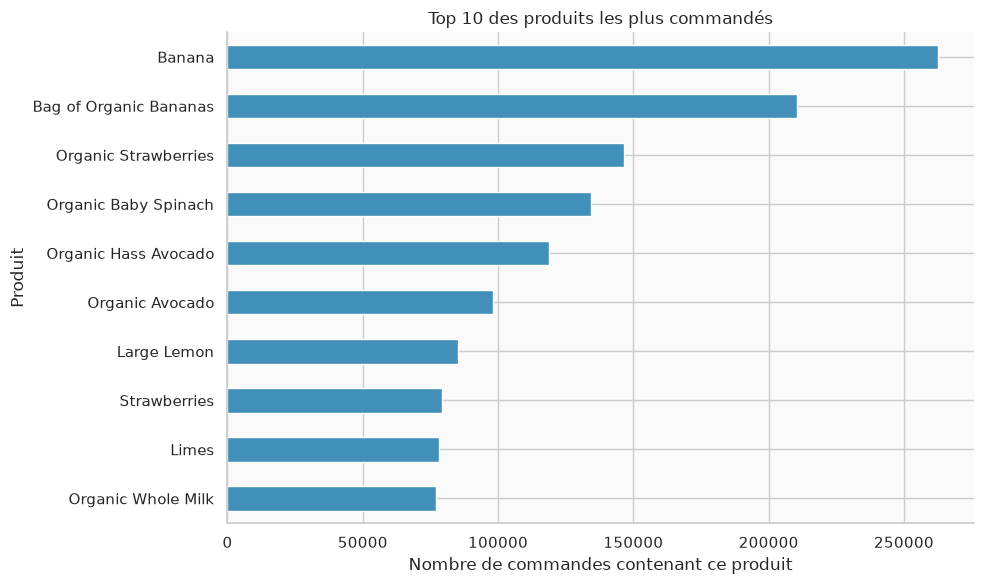

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

top_products.sort_values().plot(kind="barh", ax=ax, color="#4290ba")

ax.set_xlabel("Nombre de commandes contenant ce produit")
ax.set_ylabel("Produit")
ax.set_title("Top 10 des produits les plus commandés")

plt.tight_layout()
plt.show()


Sur ces 10 produits, **6 sont explicitement labellisés "Organic"**, et les 4 restants 
sont tous des fruits frais non transformés (bananes, citrons, fraises, limes). Aucun 
produit transformé, emballé ou de longue conservation ne figure dans ce top 10.

### Conclusion

Le magasin est fréquenté par une clientèle qui privilégie fortement les produits frais 
et bio. La banane (simple ou bio) arrive largement en tête, ce qui en fait le produit 
le plus incontournable du magasin. Ce résultat suggère que les rayons "fruits et légumes" et "bio" jouent un rôle central dans l'attractivité globale du magasin, bien plus que les rayons de produits transformés.

### Implication business

- **Gestion des stocks** : ces 10 produits doivent avoir une priorité absolue dans la 
  chaîne d'approvisionnement — une rupture de stock sur la banane ou les fraises bio 
  aurait un impact direct et visible sur un très grand nombre de clients
- **Mise en avant** : ces produits pourraient être placés stratégiquement (entrée de 
  magasin, tête de gondole) pour capter l'attention dès l'arrivée du client
- **Développement de l'offre bio** : vu la place massive du "Organic" dans ce classement, élargir la gamme bio (nouvelles références, plus de variété) semble être une piste de croissance pertinente
- **Stratégie prix** : ces produits, très demandés, pourraient servir de produits d'appel (prix légèrement réduit) pour attirer du trafic, sachant qu'ils sont déjà les moteurs naturels de fréquentation
  

## Question 3 : Quels sont les produits les moins achetés ?

**Pourquoi cette question ?**
Identifier les produits qui se vendent très peu permet au magasin de repenser son 
catalogue : faut-il les retirer, les mettre en promotion pour écouler le stock, ou 
les repositionner différemment en rayon ?

**Comment on calcule ça ?**
Comme pour les bestsellers, on compte combien de fois chaque produit apparaît dans 
les commandes. Mais ici, il faut faire attention : certains produits du catalogue 
n'ont peut-être jamais été commandés du tout, et n'apparaîtront donc même pas dans 
notre comptage. On distingue donc deux choses : les produits jamais commandés, et 
les produits commandés mais très rarement.

Les produits jamais commandés

In [4]:
from src.data_loader import load_raw_data

raw = load_raw_data(raw_dir="../data/raw")
products = raw["products"]

all_products = set(products["product_name"])
ordered_products = set(data["product_name"])
never_ordered = all_products - ordered_products

print(f"Nombre total de produits au catalogue : {len(all_products):,}")
print(f"Nombre de produits jamais commandés : {len(never_ordered):,}")
print(f"Soit {len(never_ordered) / len(all_products) * 100:.1f}% du catalogue")

Nombre total de produits au catalogue : 49,688
Nombre de produits jamais commandés : 263
Soit 0.5% du catalogue


### Observation

Ce chiffre est très faible : cela signifie que la quasi-totalité des produits référencés 
par le magasin trouve preneur, au moins occasionnellement. Il n'y a donc pas de problème 
massif de produits "morts" ou mal référencés dans le catalogue.

In [6]:
product_counts = data["product_name"].value_counts()

least_bought = product_counts.sort_values().head(10)
least_bought

product_name
Parchment Tulip Cups                     1
Kiddy Cutlery                            1
Maxtra Cartridge Water Filter Refills    1
Spicy Black Bean Veggie Burger           1
All-Natural Irish Style Oatmeal          1
Corn Original Ritz                       1
Organic Rough Cut Sugar Cubes            1
Chocolate Chip Cookie Chips              1
Original Hand Sanitizer                  1
8\" Vegan Chocolate Cake                 1
Name: count, dtype: int64

In [7]:
count_ordered_once = (product_counts == 1).sum()
total_ordered_products = len(product_counts)

print(f"Produits commandés une seule fois : {count_ordered_once:,}")
print(f"Sur un total de {total_ordered_products:,} produits ayant été commandés au moins une fois")
print(f"Soit {count_ordered_once / total_ordered_products * 100:.1f}%")

Produits commandés une seule fois : 874
Sur un total de 49,425 produits ayant été commandés au moins une fois
Soit 1.8%
